In [2]:
!nvidia-smi
!pip install -q timm wandb albumentations

Sat Nov  7 21:18:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
from google.colab import drive
drive.mount("/content/drive")

!cp /content/drive/MyDrive/retinopatia/aptos_384.zip /content/
!unzip -q -o /content/aptos_384.zip -d /content/data
!ls /content/data/aptos_384/imagenes | wc -l

Mounted at /content/drive
3583


In [4]:
import random
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Parámetros
SEMILLA = 42
IMG = 384
BATCH = 16
NUM_CLASES = 5
NOMBRES = {0: "Sin RD", 1: "Leve", 2: "Moderada", 3: "Severa", 4: "Proliferativa"}
ORDEN = list(NOMBRES.values())

# Rutas
DATOS = Path("/content/data/aptos_384")
IMAGENES = DATOS / "imagenes"
DRIVE = Path("/content/drive/MyDrive/retinopatia")
CHECKPOINTS = DRIVE / "checkpoints"
RESULTADOS = DRIVE / "resultados"
for carpeta in (CHECKPOINTS, RESULTADOS):
    carpeta.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE)

def fijar_semilla(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.cuda.manual_seed_all(semilla)

fijar_semilla(SEMILLA)

# Partición
df = pd.read_csv(DRIVE / "particion.csv")
df["path"] = df["id_code"].map(lambda x: str(IMAGENES / f"{x}.png"))
assert all(Path(p).exists() for p in df["path"]), "Faltan imágenes"
print(df["particion"].value_counts())

Dispositivo: cuda
particion
train    2507
val       542
test      534
Name: count, dtype: int64


In [5]:
import wandb
from google.colab import userdata

wandb.login(key=userdata.get("WANDB_API_KEY"))

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: diegomachadotovar4 (diegomachadotovar4-unillanos) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [6]:
def normalizar_color(img_rgb, sigma_rel=30, radio_rel=0.47):
    tam = img_rgb.shape[0]

    # 1. Restar la iluminación general y resaltar el detalle local
    desenfoque = cv2.GaussianBlur(img_rgb, (0, 0), tam / sigma_rel)
    img = cv2.addWeighted(img_rgb, 4, desenfoque, -4, 128)

    # 2. Máscara circular igual para todas las imágenes
    mascara = np.zeros((tam, tam), dtype=np.uint8)
    cv2.circle(mascara, (tam // 2, tam // 2), int(tam * radio_rel), 1, -1)
    return img * mascara[:, :, None]

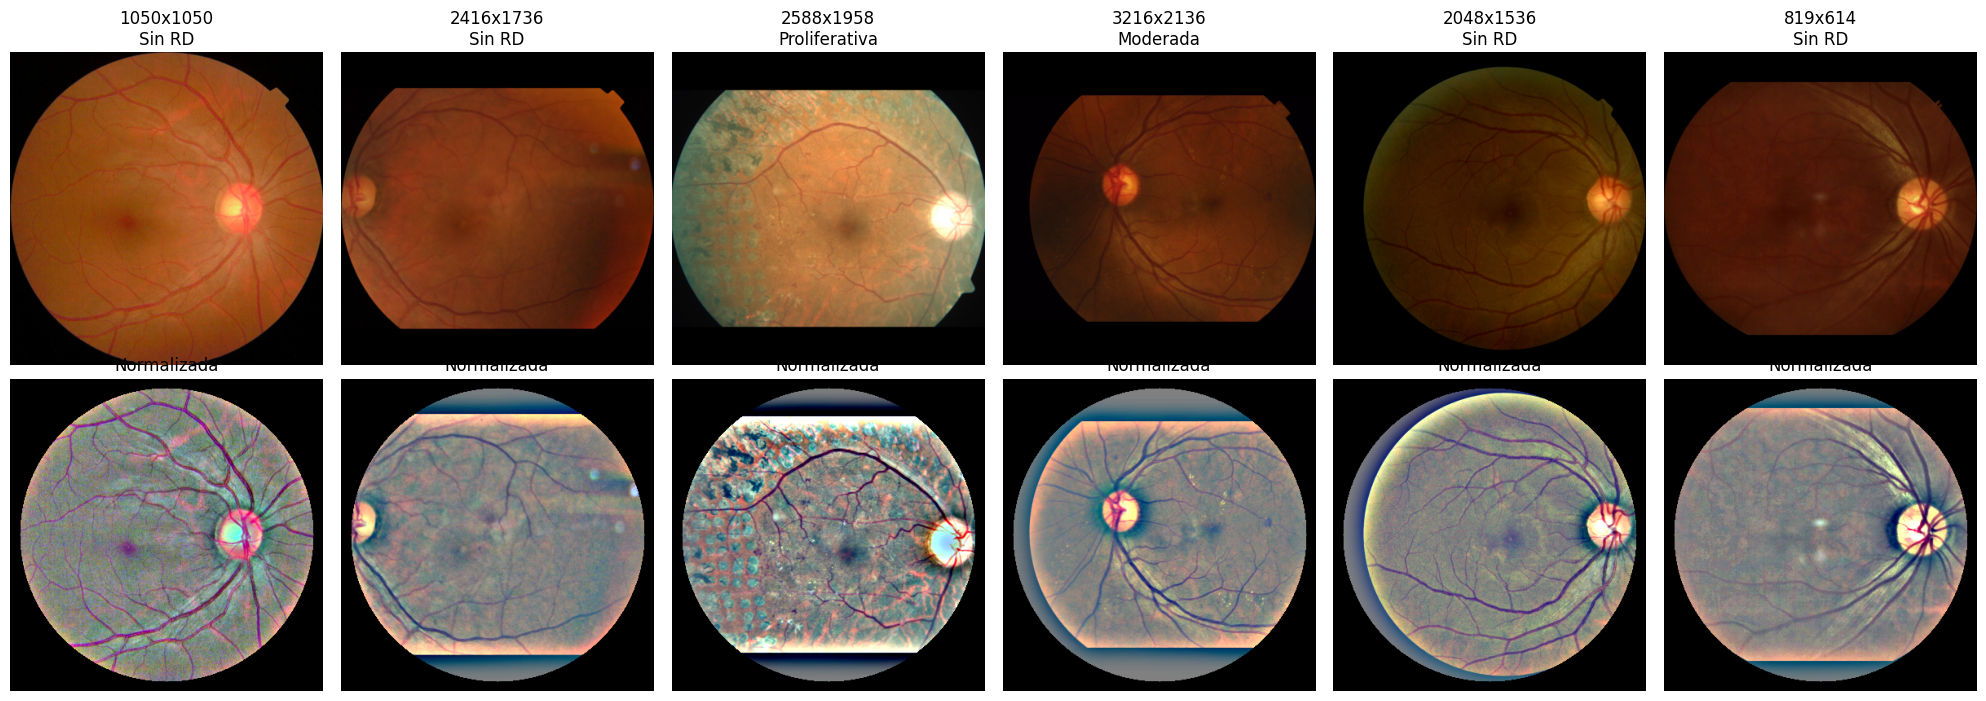

In [7]:
top = df["tamano"].value_counts().head(6).index
fig, axes = plt.subplots(2, 6, figsize=(20, 7))

for i, t in enumerate(top):
    f = df[df["tamano"] == t].sample(1, random_state=SEMILLA).iloc[0]
    img = cv2.cvtColor(cv2.imread(f["path"]), cv2.COLOR_BGR2RGB)
    axes[0, i].imshow(img)
    axes[0, i].set_title(f"{t}\n{f['clase']}")
    axes[1, i].imshow(normalizar_color(img))
    axes[1, i].set_title("Normalizada")

for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTADOS / "normalizacion_color.png", dpi=150)
plt.show()

In [8]:
MEDIA = (0.485, 0.456, 0.406)
DESV = (0.229, 0.224, 0.225)

tf_train = A.Compose([
    A.Resize(IMG, IMG),
    A.Rotate(limit=180, border_mode=cv2.BORDER_CONSTANT, p=0.8),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Affine(scale=(0.9, 1.1), p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.5),
    A.Normalize(mean=MEDIA, std=DESV),
    ToTensorV2(),
])

tf_eval = A.Compose([
    A.Resize(IMG, IMG),
    A.Normalize(mean=MEDIA, std=DESV),
    ToTensorV2(),
])

In [9]:
class RetinaDataset(Dataset):
    def __init__(self, df, transform):
        self.rutas = df["path"].tolist()
        self.etiquetas = df["diagnosis"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.rutas)

    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(self.rutas[i]), cv2.COLOR_BGR2RGB)
        img = normalizar_color(img)
        img = self.transform(image=img)["image"]
        return img, self.etiquetas[i]


def crear_loaders(df_train, df_val, sobremuestreo=True):
    ds_train = RetinaDataset(df_train, tf_train)
    ds_val = RetinaDataset(df_val, tf_eval)

    if sobremuestreo:
        conteo = df_train["diagnosis"].value_counts()
        pesos = df_train["diagnosis"].map(1.0 / conteo).values
        sampler = WeightedRandomSampler(
            torch.as_tensor(pesos, dtype=torch.double),
            num_samples=len(df_train),
            replacement=True,
        )
        dl_train = DataLoader(ds_train, batch_size=BATCH, sampler=sampler,
                              num_workers=2, pin_memory=True, drop_last=True)
    else:
        dl_train = DataLoader(ds_train, batch_size=BATCH, shuffle=True,
                              num_workers=2, pin_memory=True, drop_last=True)

    dl_val = DataLoader(ds_val, batch_size=BATCH * 2, shuffle=False,
                        num_workers=2, pin_memory=True)
    return dl_train, dl_val

Clases en una época con sobremuestreo:
Sin RD           236
Leve             247
Moderada         252
Severa           271
Proliferativa    247
Name: count, dtype: int64

Forma del lote: (16, 3, 384, 384)


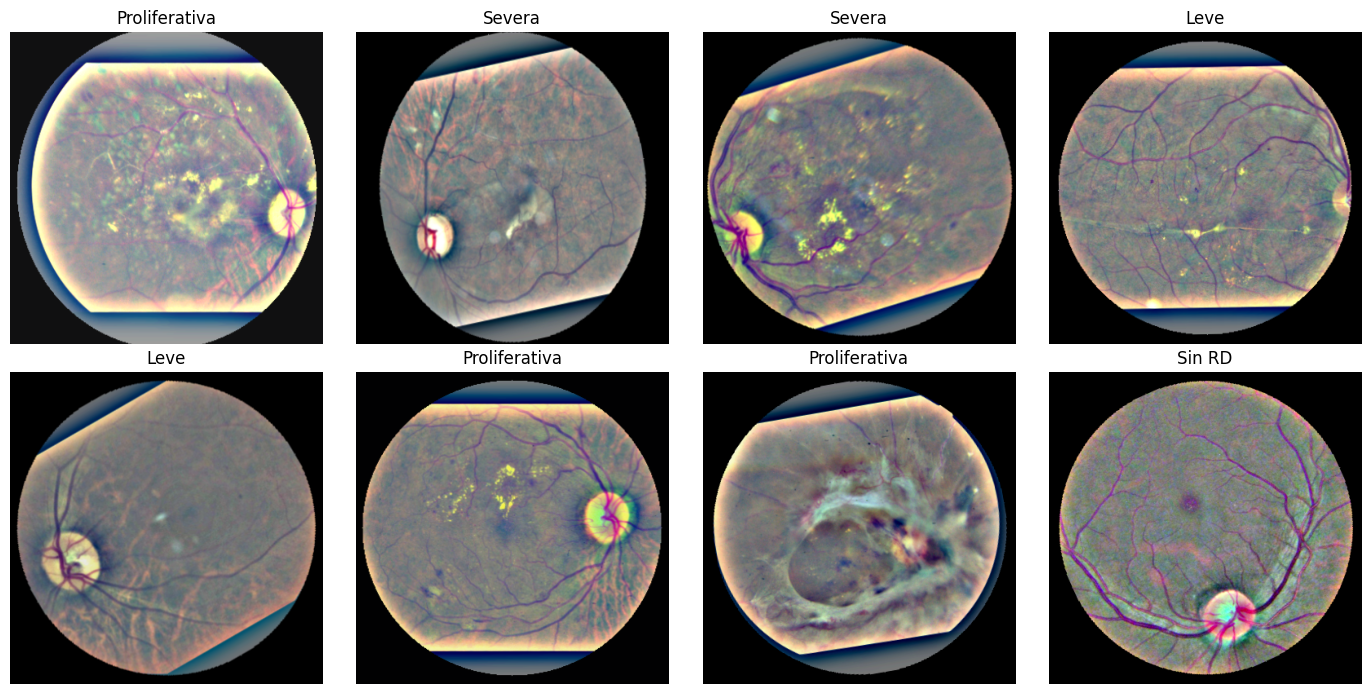

In [10]:
fold = 0
f_train = df[(df["particion"] == "train") & (df["fold"] != fold)]
f_val = df[(df["particion"] == "train") & (df["fold"] == fold)]
dl_train, dl_val = crear_loaders(f_train, f_val)

# Balance real del sampler en una época
indices = list(dl_train.sampler)
print("Clases en una época con sobremuestreo:")
print(pd.Series(f_train["diagnosis"].values[indices]).map(NOMBRES).value_counts().reindex(ORDEN))

# Un lote de ejemplo
imgs, etiquetas = next(iter(dl_train))
print("\nForma del lote:", tuple(imgs.shape))

media = torch.tensor(MEDIA).view(3, 1, 1)
desv = torch.tensor(DESV).view(3, 1, 1)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, img, y in zip(axes.flat, imgs[:8], etiquetas[:8]):
    ax.imshow((img * desv + media).permute(1, 2, 0).clamp(0, 1).numpy())
    ax.set_title(NOMBRES[int(y)])
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTADOS / "lote_aumentado.png", dpi=150)
plt.show()